# Uncertainty analyses

The purpose of this notebook is to assess the uncertainty on various climate metrics due to uncertainty in input climate settings relative to aviation species (sensitivity to emissions, ERF/RF, efficacy). The calculations (Monte Carlo experiments) leverage the Python library [SALib](https://salib.readthedocs.io/en/latest/), which could be used in future work to run sensitivity analyses.

Note that the uncertainty analyses a ran using the surrogate models instead of the full climate models.

In [1]:
# Basic libraries
%load_ext autoreload
%autoreload 2

import math
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from pandas import read_csv
from SALib.sample import latin

# From AeroCM
from aerocm.climate_models.aviation_climate_simulation import AviationClimateSimulation
from aerocm.climate_models.fair_climate_model import FairClimateModel
from aeromaps import create_process

# Sensitivity analysis
from SALib.analyze import sobol
from SALib import ProblemSpec

## 1. Wrap metrics calculation in function

In [2]:
#Fair - Lee 2021
process_climate = create_process(configuration_file="data_ecats/config_files_update/config_is2medium_sulfur.yaml")

# --- Process climate ---
climate_model = process_climate.models["climate_model"].climate_model
species_settings = process_climate.models["climate_model"].species_settings
model_settings  = process_climate.models["climate_model"].model_settings

In [3]:
# --- Set parameters ---
start_year = 1940  # start year of simulation
end_year = 2070  # end year of simulation

scenario = "RCP45"

# Inventory IS2
emissions_data_df = read_csv("is2_medium.csv", delimiter=";")
emissions_data = emissions_data_df.values

years_data = emissions_data[:, 0]
co2_emissions_data = emissions_data[:, 1]
distance_data = emissions_data[:, 2]
contrails_correction_factors_data = emissions_data[:, 3]
nox_emissions_data = emissions_data[:, 4]
h2o_emissions_data = emissions_data[:, 5]
soot_emissions_data = emissions_data[:, 6]
sulfur_emissions_data = emissions_data[:, 7]
h2_leakage_data = emissions_data[:, 8]

species_inventory = {
    "CO2": co2_emissions_data * 1e9,  # [Mt to kg]
    "Contrails": distance_data,
    "Contrails correction factors": contrails_correction_factors_data,
    "NOx": nox_emissions_data * 1e9,
    "H2O": h2o_emissions_data * 1e9,
    "Soot": soot_emissions_data * 1e9,
    "Sulfur": sulfur_emissions_data * 1e9,
    "H2 leakage": h2_leakage_data * 1e9,
}

# Inventory IS0
emissions_is0_data_df = read_csv("is0_medium.csv", delimiter=";")
emissions_is0_data = emissions_is0_data_df.values

years_is0_data = emissions_is0_data[:, 0]
co2_emissions_is0_data = emissions_is0_data[:, 1]
distance_is0_data = emissions_is0_data[:, 2]
contrails_correction_factors_is0_data = emissions_is0_data[:, 3]
nox_emissions_is0_data = emissions_is0_data[:, 4]
h2o_emissions_is0_data = emissions_is0_data[:, 5]
soot_emissions_is0_data = emissions_is0_data[:, 6]
sulfur_emissions_is0_data = emissions_is0_data[:, 7]
h2_leakage_is0_data = emissions_is0_data[:, 8]

species_inventory_is0 = {
    "CO2": co2_emissions_is0_data * 1e9,  # [Mt to kg]
    "Contrails": distance_is0_data,
    "Contrails correction factors": contrails_correction_factors_is0_data,
    "NOx": nox_emissions_is0_data * 1e9,
    "H2O": h2o_emissions_is0_data * 1e9,
    "Soot": soot_emissions_is0_data * 1e9,
    "Sulfur": sulfur_emissions_is0_data * 1e9,
    "H2 leakage": h2_leakage_is0_data * 1e9,
}

In [4]:
def climate_calculation(params_sample, start_year, end_year, species_inventory, scenario):
    sensitivity_rf_contrails = params_sample[0]
    efficacy_erf_contrails = params_sample[1]
    sensitivity_rf_sulfur = params_sample[2]

    species_settings = {
        "Contrails": {
            "sensitivity_rf": sensitivity_rf_contrails,
            "ratio_erf_rf": 0.55,
            "efficacy_erf": efficacy_erf_contrails
        },
        "Sulfur - ACI": {
            "sensitivity_rf": sensitivity_rf_sulfur
        }
    }
    
    model_settings = {"background_scenario":scenario}
    scenario = model_settings.get("background_scenario", "N/A")
    
    results = AviationClimateSimulation(
        climate_model, 
        start_year, 
        end_year, 
        species_inventory=species_inventory,
        species_settings=species_settings,
        model_settings=model_settings
    ).run(return_xr=True)
    
    temps = results['temperature']
    erf = results['effective_radiative_forcing']
    non_co2_species = [
        "Contrails",
        "NOx - ST O3",
        "NOx - CH4 and induced",
        "H2O",
        "Soot - ARI",
        "Sulfur - ARI",
        "Soot - ACI",
        "Sulfur - ACI"
    ]

    total_species = [
        "CO2",
        "Contrails",
        "NOx - ST O3",
        "NOx - CH4 and induced",
        "H2O",
        "Soot - ARI",
        "Sulfur - ARI",
        "Soot - ACI",
        "Sulfur - ACI"
    ]
    
    total = temps.sel(species=total_species).sum(dim="species")
    co2 = temps.sel(species="CO2")
    non_co2 = temps.sel(species=non_co2_species).sum(dim="species")

    total_erf = erf.sel(species=total_species).sum(dim="species")
    co2_erf = erf.sel(species="CO2")
    non_co2_erf = erf.sel(species=non_co2_species).sum(dim="species")

    return np.stack([
        total.values,
        co2.values,
        non_co2.values,
        temps.sel(species="Contrails").values,
        temps.sel(species="NOx - ST O3").values,
        temps.sel(species="NOx - CH4 and induced").values,
        temps.sel(species="H2O").values,
        temps.sel(species="Soot - ARI").values,
        temps.sel(species="Sulfur - ARI").values,
        temps.sel(species="Soot - ACI").values,
        temps.sel(species="Sulfur - ACI").values,

        total_erf.values,
        co2_erf.values,
        non_co2_erf.values,
        erf.sel(species="Contrails").values,
        erf.sel(species="NOx - ST O3").values,
        erf.sel(species="NOx - CH4 and induced").values,
        erf.sel(species="H2O").values,
        erf.sel(species="Soot - ARI").values,
        erf.sel(species="Sulfur - ARI").values,
        erf.sel(species="Soot - ACI").values,
        erf.sel(species="Sulfur - ACI").values
    ], axis=0)


## 2. Uncertainty analysis

### a) Define uncertain inputs

In [5]:
# SALIb
sp_metrics = ProblemSpec({
    'names': ['sensitivity_rf_contrails', 'efficacy_erf_contrails', 'sensitivity_rf_sulfur_aci'],
    'bounds': [
        [1.2e-12*0.73, 1.2e-12*1.27], 
        [0.38, 0.157],
        [-11.35e-11*1.52,-11.35e-11*0.48],
    ],
    'dists': ["unif", "norm", "unif"]
})

### b) Run analysis

In [6]:
# Initialiase Monte Carlo
N = 200  # number of samples
param_values = latin.sample(sp_metrics, N)

C:\Users\t.planes\PycharmProjects\AeroMAPS\.venv\Lib\site-packages\SALib\util\__init__.py:302: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  unique_group_names = pd.unique(groups)


In [7]:
# Run MC
years = end_year - start_year + 1
data = np.zeros((N, 22, years))
data_is0 = np.zeros((N, 22, years))

# Monte Carlo
for i in range(N):
    data[i] = climate_calculation(
        param_values[i],
        start_year,
        end_year,
        species_inventory,
        scenario
    )
for i in range(N):
    data_is0[i] = climate_calculation(
        param_values[i],
        start_year,
        end_year,
        species_inventory_is0,
        scenario
    )

### c) Plot

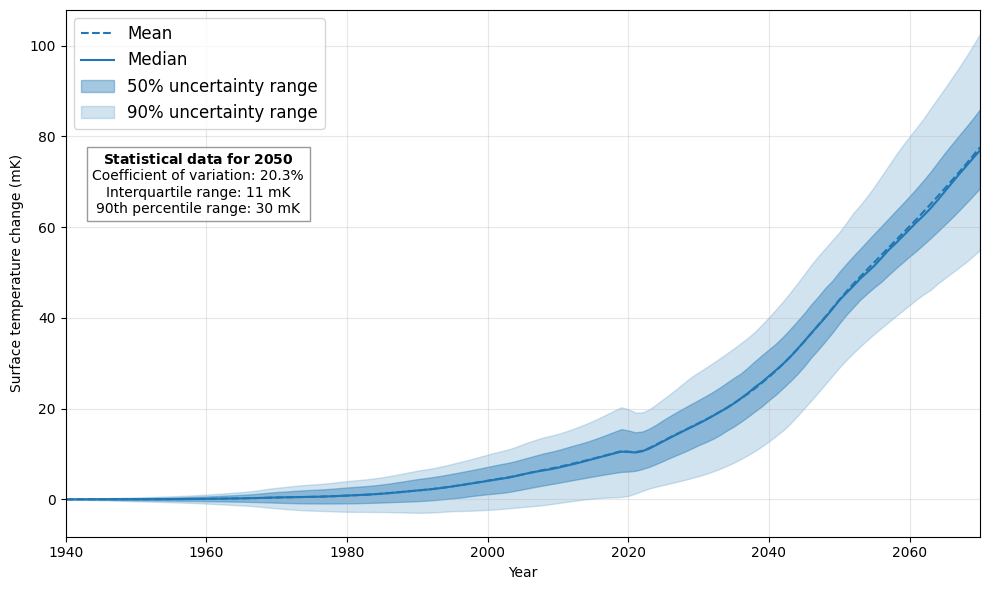

In [8]:
# Années simulées
years_array = np.arange(start_year, end_year + 1)

# Température totale : sortie 0 de climate_calculation
temperature = 1000*data[:, 0, :]  # (N, years)

# Statistiques sur les simulations
temp_mean = np.mean(temperature, axis=0)
temp_median = np.median(temperature, axis=0)
temp_low = np.percentile(temperature, 25, axis=0)
temp_high = np.percentile(temperature, 75, axis=0)
temp_very_low = np.percentile(temperature, 5, axis=0)
temp_very_high = np.percentile(temperature, 95, axis=0)

# Coefficient de variation pour 2050
temp_last_year = temperature[:, 2050-1940]
temp_mean_last_year = np.mean(temp_last_year)
temp_median_last_year = np.median(temp_last_year)
temp_std_last_year = np.std(temp_last_year)
temp_cv_last_year = temp_std_last_year / abs(temp_mean_last_year) * 100
temp_low_last_year = np.percentile(temp_last_year, 25)
temp_high_last_year = np.percentile(temp_last_year, 75)
temp_very_low_last_year = np.percentile(temp_last_year, 5)
temp_very_high_last_year = np.percentile(temp_last_year, 95)

# Tracé
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(years_array, temp_mean, label="Mean",
        color="tab:blue", linestyle="--")

ax.plot(years_array, temp_median, label="Median",
        color="tab:blue")

ax.fill_between(years_array, temp_low, temp_high,
                color="tab:blue", alpha=0.4,
                label="50% uncertainty range")

ax.fill_between(years_array, temp_very_low, temp_very_high,
                color="tab:blue", alpha=0.2,
                label="90% uncertainty range")

# Statistiques à l'intérieur du graphique
stats_text = (
    r"$\bf{Statistical\ data\ for\ 2050}$" + "\n"
    f"Coefficient of variation: {temp_cv_last_year:.1f}%\n"
    f"Interquartile range: "
    f"{temp_high_last_year - temp_low_last_year:.0f} mK\n"
    f"90th percentile range: "
    f"{temp_very_high_last_year - temp_very_low_last_year:.0f} mK"
)

ax.text(
    0.145, 0.73,
    stats_text,
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=10,
    bbox=dict(facecolor="white", alpha=0.8, edgecolor="gray")
)

ax.set_xlabel("Year")
ax.set_ylabel("Surface temperature change (mK)")
ax.set_xlim(1940, 2070)
ax.legend(loc="best", fontsize=12)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("uncertainty.png", dpi=300, bbox_inches="tight")
plt.show()

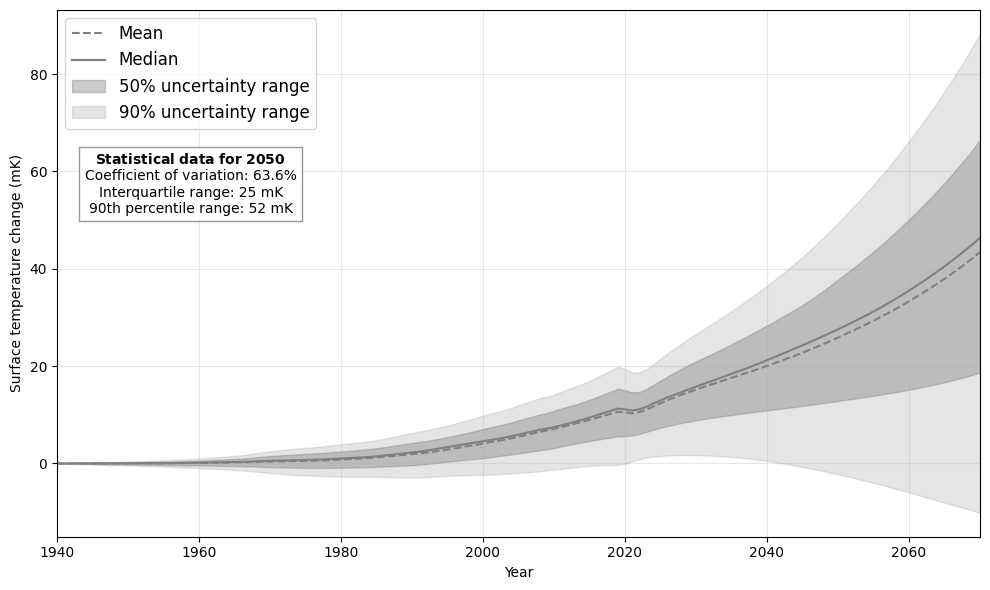

In [14]:
# Années simulées
years_array = np.arange(start_year, end_year + 1)

# Température totale : sortie 0 de climate_calculation
temperature = 1000*data_is0[:, 0, :]  # (N, years)

# Statistiques sur les simulations
temp_mean = np.mean(temperature, axis=0)
temp_median = np.median(temperature, axis=0)
temp_low = np.percentile(temperature, 25, axis=0)
temp_high = np.percentile(temperature, 75, axis=0)
temp_very_low = np.percentile(temperature, 5, axis=0)
temp_very_high = np.percentile(temperature, 95, axis=0)

# Coefficient de variation pour 2050
temp_last_year = temperature[:, 2050-1940]
temp_mean_last_year = np.mean(temp_last_year)
temp_median_last_year = np.median(temp_last_year)
temp_std_last_year = np.std(temp_last_year)
temp_cv_last_year = temp_std_last_year / abs(temp_mean_last_year) * 100
temp_low_last_year = np.percentile(temp_last_year, 25)
temp_high_last_year = np.percentile(temp_last_year, 75)
temp_very_low_last_year = np.percentile(temp_last_year, 5)
temp_very_high_last_year = np.percentile(temp_last_year, 95)

# Tracé
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(years_array, temp_mean, label="Mean",
        color="grey", linestyle="--")

ax.plot(years_array, temp_median, label="Median",
        color="grey")

ax.fill_between(years_array, temp_low, temp_high,
                color="grey", alpha=0.4,
                label="50% uncertainty range")

ax.fill_between(years_array, temp_very_low, temp_very_high,
                color="grey", alpha=0.2,
                label="90% uncertainty range")

# Statistiques à l'intérieur du graphique
stats_text = (
    r"$\bf{Statistical\ data\ for\ 2050}$" + "\n"
    f"Coefficient of variation: {temp_cv_last_year:.1f}%\n"
    f"Interquartile range: "
    f"{temp_high_last_year - temp_low_last_year:.0f} mK\n"
    f"90th percentile range: "
    f"{temp_very_high_last_year - temp_very_low_last_year:.0f} mK"
)

ax.text(
    0.145, 0.73,
    stats_text,
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=10,
    bbox=dict(facecolor="white", alpha=0.8, edgecolor="gray")
)

ax.set_xlabel("Year")
ax.set_ylabel("Surface temperature change (mK)")
ax.set_xlim(1940, 2070)
ax.legend(loc="best", fontsize=12)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("uncertainty_is0.png", dpi=300, bbox_inches="tight")
plt.show()

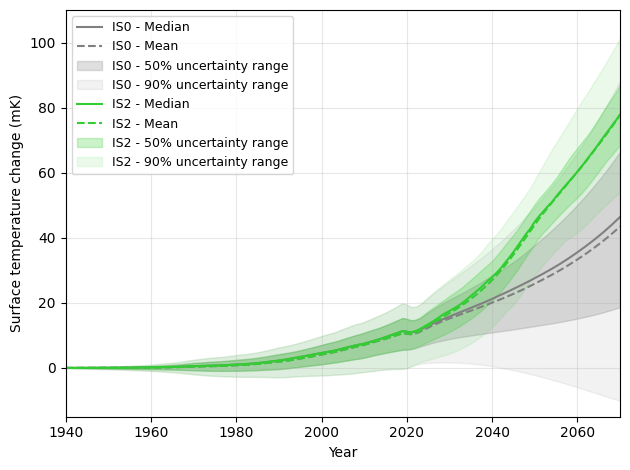

In [21]:
# Années simulées
years_array = np.arange(start_year, end_year + 1)
data_is1=data

# ============================================================
# SCÉNARIO 1
# ============================================================
temperature_1 = 1000 * data_is0[:, 0, :]  # (N, years)

temp_mean_1 = np.mean(temperature_1, axis=0)
temp_median_1 = np.median(temperature_1, axis=0)
temp_low_1 = np.percentile(temperature_1, 25, axis=0)
temp_high_1 = np.percentile(temperature_1, 75, axis=0)
temp_very_low_1 = np.percentile(temperature_1, 5, axis=0)
temp_very_high_1 = np.percentile(temperature_1, 95, axis=0)

# Statistiques pour 2050
idx_2050 = 2050 - start_year
temp_last_year_1 = temperature_1[:, idx_2050]

temp_mean_last_year_1 = np.mean(temp_last_year_1)
temp_std_last_year_1 = np.std(temp_last_year_1)
temp_cv_last_year_1 = (
    temp_std_last_year_1 / abs(temp_mean_last_year_1) * 100
    if temp_mean_last_year_1 != 0 else np.nan
)

temp_low_last_year_1 = np.percentile(temp_last_year_1, 25)
temp_high_last_year_1 = np.percentile(temp_last_year_1, 75)
temp_very_low_last_year_1 = np.percentile(temp_last_year_1, 5)
temp_very_high_last_year_1 = np.percentile(temp_last_year_1, 95)


# ============================================================
# SCÉNARIO 2
# ============================================================
temperature_2 = 1000 * data_is1[:, 0, :]  # (N, years)

temp_mean_2 = np.mean(temperature_2, axis=0)
temp_median_2 = np.median(temperature_2, axis=0)
temp_low_2 = np.percentile(temperature_2, 25, axis=0)
temp_high_2 = np.percentile(temperature_2, 75, axis=0)
temp_very_low_2 = np.percentile(temperature_2, 5, axis=0)
temp_very_high_2 = np.percentile(temperature_2, 95, axis=0)

# Statistiques pour 2050
temp_last_year_2 = temperature_2[:, idx_2050]

temp_mean_last_year_2 = np.mean(temp_last_year_2)
temp_std_last_year_2 = np.std(temp_last_year_2)
temp_cv_last_year_2 = (
    temp_std_last_year_2 / abs(temp_mean_last_year_2) * 100
    if temp_mean_last_year_2 != 0 else np.nan
)

temp_low_last_year_2 = np.percentile(temp_last_year_2, 25)
temp_high_last_year_2 = np.percentile(temp_last_year_2, 75)
temp_very_low_last_year_2 = np.percentile(temp_last_year_2, 5)
temp_very_high_last_year_2 = np.percentile(temp_last_year_2, 95)


# ============================================================
# TRACÉ DES DEUX SCÉNARIOS
# ============================================================
fig, ax = plt.subplots()

# Scénario 1
ax.plot(
    years_array, temp_median_1,
    label="IS0 - Median",
    color="grey"
)

ax.plot(
    years_array, temp_mean_1,
    label="IS0 - Mean",
    color="grey",
    linestyle="--"
)

ax.fill_between(
    years_array, temp_low_1, temp_high_1,
    color="grey", alpha=0.25,
    label="IS0 - 50% uncertainty range"
)

ax.fill_between(
    years_array, temp_very_low_1, temp_very_high_1,
    color="grey", alpha=0.10,
    label="IS0 - 90% uncertainty range"
)

# Scénario 2
ax.plot(
    years_array, temp_median_2,
    label="IS2 - Median",
    color="limegreen"
)

ax.plot(
    years_array, temp_mean_2,
    label="IS2 - Mean",
    color="limegreen",
    linestyle="--"
)

ax.fill_between(
    years_array, temp_low_2, temp_high_2,
    color="limegreen", alpha=0.25,
    label="IS2 - 50% uncertainty range"
)

ax.fill_between(
    years_array, temp_very_low_2, temp_very_high_2,
    color="limegreen", alpha=0.10,
    label="IS2 - 90% uncertainty range"
)


## ============================================================
## STATISTIQUES POUR 2050
## ============================================================
#stats_text = (
#    r"$\bf{Statistical\ data\ for\ 2050}$" + "\n\n"
#    "Scenario 1:\n"
#    f"Coefficient of variation: {temp_cv_last_year_1:.1f}%\n"
#    f"Interquartile range: "
#    f"{temp_high_last_year_1 - temp_low_last_year_1:.0f} mK\n"
#    f"90% range: "
#    f"{temp_very_high_last_year_1 - temp_very_low_last_year_1:.0f} mK\n\n"
#    "Scenario 2:\n"
#    f"Coefficient of variation: {temp_cv_last_year_2:.1f}%\n"
#    f"Interquartile range: "
#    f"{temp_high_last_year_2 - temp_low_last_year_2:.0f} mK\n"
#    f"90% range: "
#    f"{temp_very_high_last_year_2 - temp_very_low_last_year_2:.0f} mK"
#)
#
#ax.text(
#    0.02, 0.98,
#    stats_text,
#    transform=ax.transAxes,
#    ha="left",
#    va="top",
#    fontsize=9,
#    bbox=dict(
#        facecolor="white",
#        alpha=0.85,
#        edgecolor="gray"
#    )
#)

# Mise en forme
ax.set_xlabel("Year")
ax.set_ylabel("Surface temperature change (mK)")
ax.set_xlim(start_year, end_year)
ax.set_ylim(-15, 110)
ax.legend(loc="best", fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("uncertainty_is0_is2.png", dpi=300, bbox_inches="tight")
plt.show()

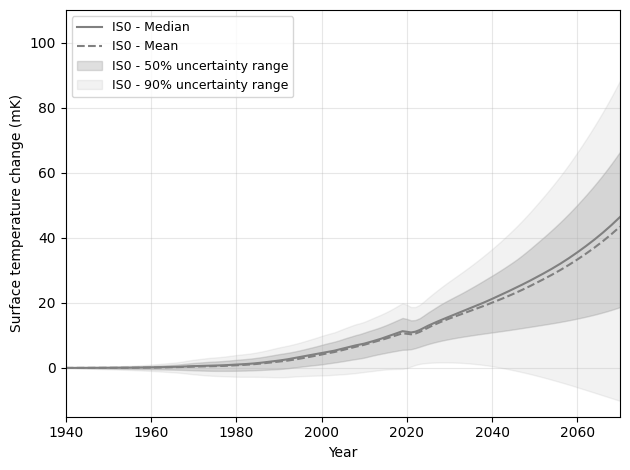

In [20]:
# Années simulées
years_array = np.arange(start_year, end_year + 1)
data_is1=data

# ============================================================
# SCÉNARIO 1
# ============================================================
temperature_1 = 1000 * data_is0[:, 0, :]  # (N, years)

temp_mean_1 = np.mean(temperature_1, axis=0)
temp_median_1 = np.median(temperature_1, axis=0)
temp_low_1 = np.percentile(temperature_1, 25, axis=0)
temp_high_1 = np.percentile(temperature_1, 75, axis=0)
temp_very_low_1 = np.percentile(temperature_1, 5, axis=0)
temp_very_high_1 = np.percentile(temperature_1, 95, axis=0)

# Statistiques pour 2050
idx_2050 = 2050 - start_year
temp_last_year_1 = temperature_1[:, idx_2050]

temp_mean_last_year_1 = np.mean(temp_last_year_1)
temp_std_last_year_1 = np.std(temp_last_year_1)
temp_cv_last_year_1 = (
    temp_std_last_year_1 / abs(temp_mean_last_year_1) * 100
    if temp_mean_last_year_1 != 0 else np.nan
)

temp_low_last_year_1 = np.percentile(temp_last_year_1, 25)
temp_high_last_year_1 = np.percentile(temp_last_year_1, 75)
temp_very_low_last_year_1 = np.percentile(temp_last_year_1, 5)
temp_very_high_last_year_1 = np.percentile(temp_last_year_1, 95)


# ============================================================
# SCÉNARIO 2
# ============================================================
temperature_2 = 1000 * data_is1[:, 0, :]  # (N, years)

temp_mean_2 = np.mean(temperature_2, axis=0)
temp_median_2 = np.median(temperature_2, axis=0)
temp_low_2 = np.percentile(temperature_2, 25, axis=0)
temp_high_2 = np.percentile(temperature_2, 75, axis=0)
temp_very_low_2 = np.percentile(temperature_2, 5, axis=0)
temp_very_high_2 = np.percentile(temperature_2, 95, axis=0)

# Statistiques pour 2050
temp_last_year_2 = temperature_2[:, idx_2050]

temp_mean_last_year_2 = np.mean(temp_last_year_2)
temp_std_last_year_2 = np.std(temp_last_year_2)
temp_cv_last_year_2 = (
    temp_std_last_year_2 / abs(temp_mean_last_year_2) * 100
    if temp_mean_last_year_2 != 0 else np.nan
)

temp_low_last_year_2 = np.percentile(temp_last_year_2, 25)
temp_high_last_year_2 = np.percentile(temp_last_year_2, 75)
temp_very_low_last_year_2 = np.percentile(temp_last_year_2, 5)
temp_very_high_last_year_2 = np.percentile(temp_last_year_2, 95)


# ============================================================
# TRACÉ DES DEUX SCÉNARIOS
# ============================================================
fig, ax = plt.subplots()

# Scénario 1
ax.plot(
    years_array, temp_median_1,
    label="IS0 - Median",
    color="grey"
)

ax.plot(
    years_array, temp_mean_1,
    label="IS0 - Mean",
    color="grey",
    linestyle="--"
)

ax.fill_between(
    years_array, temp_low_1, temp_high_1,
    color="grey", alpha=0.25,
    label="IS0 - 50% uncertainty range"
)

ax.fill_between(
    years_array, temp_very_low_1, temp_very_high_1,
    color="grey", alpha=0.10,
    label="IS0 - 90% uncertainty range"
)

## Scénario 2
#ax.plot(
#    years_array, temp_median_2,
#    label="IS2 - Median",
#    color="limegreen"
#)
#
#ax.plot(
#    years_array, temp_mean_2,
#    label="IS2 - Mean",
#    color="limegreen",
#    linestyle="--"
#)
#
#ax.fill_between(
#    years_array, temp_low_2, temp_high_2,
#    color="limegreen", alpha=0.25,
#    label="IS2 - 50% uncertainty range"
#)
#
#ax.fill_between(
#    years_array, temp_very_low_2, temp_very_high_2,
#    color="limegreen", alpha=0.10,
#    label="IS2 - 90% uncertainty range"
#)


## ============================================================
## STATISTIQUES POUR 2050
## ============================================================
#stats_text = (
#    r"$\bf{Statistical\ data\ for\ 2050}$" + "\n\n"
#    "Scenario 1:\n"
#    f"Coefficient of variation: {temp_cv_last_year_1:.1f}%\n"
#    f"Interquartile range: "
#    f"{temp_high_last_year_1 - temp_low_last_year_1:.0f} mK\n"
#    f"90% range: "
#    f"{temp_very_high_last_year_1 - temp_very_low_last_year_1:.0f} mK\n\n"
#    "Scenario 2:\n"
#    f"Coefficient of variation: {temp_cv_last_year_2:.1f}%\n"
#    f"Interquartile range: "
#    f"{temp_high_last_year_2 - temp_low_last_year_2:.0f} mK\n"
#    f"90% range: "
#    f"{temp_very_high_last_year_2 - temp_very_low_last_year_2:.0f} mK"
#)
#
#ax.text(
#    0.02, 0.98,
#    stats_text,
#    transform=ax.transAxes,
#    ha="left",
#    va="top",
#    fontsize=9,
#    bbox=dict(
#        facecolor="white",
#        alpha=0.85,
#        edgecolor="gray"
#    )
#)

# Mise en forme
ax.set_xlabel("Year")
ax.set_ylabel("Surface temperature change (mK)")
ax.set_xlim(start_year, end_year)
ax.set_ylim(-15, 110)
ax.legend(loc="best", fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("uncertainty_is0.png", dpi=300, bbox_inches="tight")
plt.show()

# Sobol

In [22]:
N_sobol = 2**9
param_values = sp_metrics.sample_sobol(
    N_sobol,
    calc_second_order=False
).samples
N_sobol_total = len(param_values)

In [23]:
# Run simulations
years = end_year - start_year + 1
data_sobol = np.zeros((N_sobol_total, 22, years))
data_is0_sobol = np.zeros((N_sobol_total, 22, years))

for i in range(N_sobol_total):
    data_sobol[i] = climate_calculation(
        param_values[i],
        start_year,
        end_year,
        species_inventory,
        scenario
    )
for i in range(N_sobol_total):
    data_is0_sobol[i] = climate_calculation(
        param_values[i],
        start_year,
        end_year,
        species_inventory_is0,
        scenario
    )

In [24]:
# Data
Y_ref = data_sobol[:, 0, 2019-1940]
Y = data_sobol[:, 0, 2050-1940]
Y_is0 = data_is0_sobol[:, 0, 2050-1940]

# Analyse Sobol

sp_metrics.set_samples(param_values)
sp_metrics.set_results(Y_ref)
sp_metrics.analyze_sobol(calc_second_order=False)
Si_ref = sp_metrics.analysis
S1_ref = Si_ref["S1"]
ST_ref = Si_ref["ST"]
S1_conf_ref = Si_ref["S1_conf"]
ST_conf_ref = Si_ref["ST_conf"]

sp_metrics.set_samples(param_values)
sp_metrics.set_results(Y)
sp_metrics.analyze_sobol(calc_second_order=False)
Si = sp_metrics.analysis
S1 = Si["S1"]
ST = Si["ST"]
S1_conf = Si["S1_conf"]
ST_conf = Si["ST_conf"]

sp_metrics.set_samples(param_values)
sp_metrics.set_results(Y_is0)
sp_metrics.analyze_sobol(calc_second_order=False)
Si_is0 = sp_metrics.analysis
S1_is0 = Si_is0["S1"]
ST_is0 = Si_is0["ST"]
S1_conf_is0 = Si["S1_conf"]
ST_conf_is0 = Si["ST_conf"]

names = sp_metrics["names"]
y = np.arange(len(names))

C:\Users\t.planes\PycharmProjects\AeroMAPS\.venv\Lib\site-packages\SALib\util\__init__.py:274: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  names = list(pd.unique(groups))


In [31]:
results = {
    "Reference (2019)": {
        "S1": S1_ref,
        "ST": ST_ref,
        "S1_conf": S1_conf_ref,
        "ST_conf": ST_conf_ref,
        "color": "black"
    },
    "IS0 (2050)": {
        "S1": S1_is0,
        "ST": ST_is0,
        "S1_conf": S1_conf_is0,
        "ST_conf": ST_conf_is0,
        "color": "grey"
    },
    "IS2 (2050)": {
        "S1": S1,
        "ST": ST,
        "S1_conf": S1_conf,
        "ST_conf": ST_conf,
        "color": "limegreen"
    }, 
}

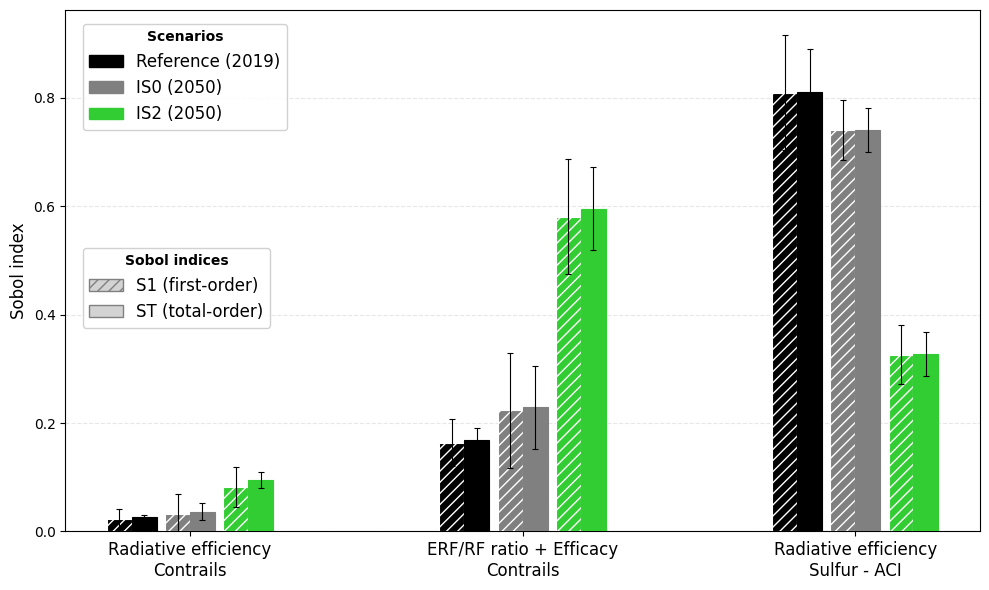

In [32]:
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(10, 6))

n_scenarios = len(results)
n_params = len(names)

bar_width = 0.075
scenario_gap = 0.025
pair_width = 2 * bar_width + scenario_gap

y = np.arange(n_params)

for i, (scenario, values) in enumerate(results.items()):

    color = values["color"]
    offset = (i - (n_scenarios - 1) / 2) * pair_width

    # S1 : indice de premier ordre
    ax.bar(
        y + offset - bar_width / 2,
        values["S1"],
        width=bar_width,
        color=color,
        hatch="///",
        edgecolor="white",
        linewidth=0.8,
        yerr=values["S1_conf"],
        capsize=2,
        error_kw={
            "ecolor": "black",
            "elinewidth": 0.8,
            "capthick": 0.8
        },
        zorder=3
    )

    # ST : indice d'ordre total
    ax.bar(
        y + offset + bar_width / 2,
        values["ST"],
        width=bar_width,
        color=color,
        edgecolor=color,
        linewidth=0.8,
        yerr=values["ST_conf"],
        capsize=2,
        error_kw={
            "ecolor": "black",
            "elinewidth": 0.8,
            "capthick": 0.8
        },
        zorder=3
    )

# Labels des paramètres
names_labels = [
    "Radiative efficiency\nContrails",
    "ERF/RF ratio + Efficacy\nContrails",
    "Radiative efficiency\nSulfur - ACI"
]

ax.set_xticks(y)
ax.set_xticklabels(names_labels, rotation=0, ha="center", fontsize=12)

ax.set_ylabel("Sobol index", fontsize=12)

# Légende des scénarios
scenario_handles = [
    Patch(
        facecolor=v["color"],
        edgecolor=v["color"],
        label=scenario
    )
    for scenario, v in results.items()
]

legend1 = ax.legend(
    handles=scenario_handles,
    title="Scenarios",
    loc="upper left",
    bbox_to_anchor=(0.01, 0.99),
    frameon=True,
    framealpha=0.9,
    fontsize=12
)
legend1.get_title().set_fontweight("bold")
ax.add_artist(legend1)

# Légende des indices de Sobol
index_handles = [
    Patch(
        facecolor="lightgray",
        edgecolor="gray",
        hatch="///",
        label="S1 (first-order)"
    ),
    Patch(
        facecolor="lightgray",
        edgecolor="gray",
        label="ST (total-order)"
    )
]

legend2 = ax.legend(
    handles=index_handles,
    title="Sobol indices",
    loc="upper left",
    bbox_to_anchor=(0.01, 0.56),
    frameon=True,
    framealpha=0.9,
    fontsize=12
)
legend2.get_title().set_fontweight("bold")

# Mise en forme
ax.grid(axis="y", alpha=0.3, linestyle="--", zorder=0)
ax.set_axisbelow(True)
ax.set_ylim(bottom=0)

plt.tight_layout()
plt.savefig("sobol_uncertainty_is.png", dpi=300, bbox_inches="tight")
plt.show()